# From RTL to GDS: A Reproducible Open-Source UART-to-VGA ASIC Design and Verification Laboratory

**IEEE SSCS Code-a-Chip Travel Grant Awards — ISSCC 2027**  
**Design Submitted for Tapeout:** Tiny Tapeout SKY26c, #847 — UART VGA Text Scroller with an Independent 2-bit ALU  
**Proposed Team Representative:** Noble G, Muthoot Institute of Technology and Science (MITS), Kochi, India  
**Technology:** SKY130; 1 × 2 Tiny Tapeout tiles  
**Public design:** [Tiny Tapeout chip listing](https://tinytapeout.com/chips/ttsky26c/tt_um_nobleg30_uart_vga_scroller) · [source repository](https://github.com/nobleg30/ttsky26c-uart-vga-scroller)  
**Notebook license:** Apache License 2.0

### Why This Project Serves as an Open-Source Design Laboratory

This notebook presents **our UART-to-VGA ASIC design, submitted for tapeout through Tiny Tapeout SKY26c,** as a reproducible, hands-on learning platform for digital ASIC design and verification.

Using publicly available Verilog RTL, open-source simulation tools, Python-based experiments, and physical implementation results, the notebook demonstrates the complete design methodology from RTL development to GDS generation.

Readers can explore the architecture, modify test inputs, execute simulations, verify functionality, and examine the physical implementation. This makes the notebook an interactive educational resource rather than simply a description of a completed ASIC design.

A reader can inspect the unchanged RTL, explore UART/VGA timing, visualize the actual font ROM, and run four separate RTL-verification checks: (i) exhaustive ALU vectors, (ii) an entire VGA raster of timing cycles, (iii) UART reception and message-buffer semantics, and (iv) the **original integrated Cocotb regression with captured VGA output frames**. The included physical-layout link connects the verified RTL to the published Tiny Tapeout layout, demonstrating the progression from RTL design and verification to physical implementation.

**Learning outcomes.** Understand mixed-function Tapeout pin mapping, compute resource-saving representation choices, reproduce RTL tests with open-source tools, understand the distinction between a Python reference model and simulated hardware, and critically assess RTL-to-layout evidence.

**Quick start (Google Colab):** choose *Runtime → Run all*. The notebook installs Icarus Verilog and the pinned Cocotb test dependencies as needed; internet access is required to clone the public repository. The full integration regression is **enabled by default**; it also saves actual RTL-derived VGA snapshots. Run time depends on the Colab instance.


## 1 · Circuit architecture and design choices

**Two independent data paths.** A synchronized 9600-baud 8-N-1 receiver converts serial bytes into compact character codes; a 32-entry × 6-bit memory feeds a combinational 5×7 bitmap font generator; the glyph is scaled by four and positioned by a frame-driven scroll offset; the TinyVGA port emits RGB222, HSYNC, and VSYNC. On separate bidirectional pins, a *combinational* 2-bit ALU performs ADD, SUB, AND, XOR. The design nominally operates at **25.175 MHz**, using **1×2 Tiny Tapeout tiles**.

**Tradeoffs:** Store only 192 bits of character codes rather than a 640×480 framebuffer; derive pixels on demand. A 32-pixel character cell with a 5×7×4-pixel glyph simplifies address arithmetic. A 2-flop UART input synchronizer reduces (but never eliminates) metastability risk. Colours are chosen from four fixed palettes rather than a programmable RGB register. This is an educational design, not a general-purpose text or graphics processor.

**Diagram interpretation.** Timing outputs have three separate consumers: `h_count`, `v_count`, and `video_active` control pixel rendering; `frame_tick` advances scrolling; `hsync` and `vsync` feed the TinyVGA pins directly. The scroll position controls glyph placement. The diagram is a logical signal-flow summary, not a netlist.

**Pin-level accuracy.** The TinyVGA port uses all eight dedicated output pins: `uo_out[0]` = R1, `[1]` = G1, `[2]` = B1, `[3]` = **VSYNC**, `[4]` = R0, `[5]` = G0, `[6]` = B0, `[7]` = **HSYNC**. Thus RGB222 comprises six interleaved pins, not a contiguous `uo_out[0:5]` or `uo_out[0:6]` bus. UART RX is on `ui_in[3]`, while the independent 2-bit ALU is on `uio_in[5:0]`/`uio_out[7:6]`.


**Detailed figure.** The diagram below expands UART synchronization, the 8-N-1 receiver FSM, the ASCII-to-6-bit code encoder, 32×6-bit message registers, row and pixel selection, colour mux, raster counters, frame-tick-driven scroll positioning, and the independent 2-bit ALU. Cross-panel lines and I/O paths are summarized at the functional level; refer to the source RTL for exact signal dependencies. The TinyVGA and ALU buses are completely separate.


**Pin-mapping audit:** VGA is on `uo_out[7:0]` (HSYNC on bit 7, VSYNC on bit 3; RGB on the other six bits). The independent 2-bit ALU accepts A/B/SEL on `uio_in[5:0]` and drives only `uio_out[7:6]`; `uio_oe = 8'b11000000` is a constant. No UART, raster-timing, or display signals connect to the ALU.


In [1]:
import sys, os, re, json, hashlib, subprocess, shutil, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

REPO_URL = 'https://github.com/nobleg30/ttsky26c-uart-vga-scroller.git'
CHIP_URL = 'https://tinytapeout.com/chips/ttsky26c/tt_um_nobleg30_uart_vga_scroller'
TOP = 'tt_um_nobleg30_uart_vga_scroller'
FCLK = 25_175_000
UART_DIVISOR = 2622
RTL_ROOT = Path('/content/ttsky26c-uart-vga-scroller') if Path('/content').exists() else Path.cwd() / 'ttsky26c-uart-vga-scroller'
RESULTS = Path.cwd() / 'code_a_chip_results'
RESULTS.mkdir(exist_ok=True)

def cmd(args, cwd=None, timeout=240):
    completed = subprocess.run(args, cwd=cwd, text=True, capture_output=True, timeout=timeout)
    if completed.returncode:
        raise RuntimeError(f"Command failed: {args}\nSTDOUT:\n{completed.stdout[-4000:]}\nSTDERR:\n{completed.stderr[-4000:]}")
    return completed.stdout.strip()

print('Python:', sys.version.split()[0], '| numpy:', np.__version__)

Python: 3.13.18 | numpy: 2.1.3


###Detailed RTL architecture

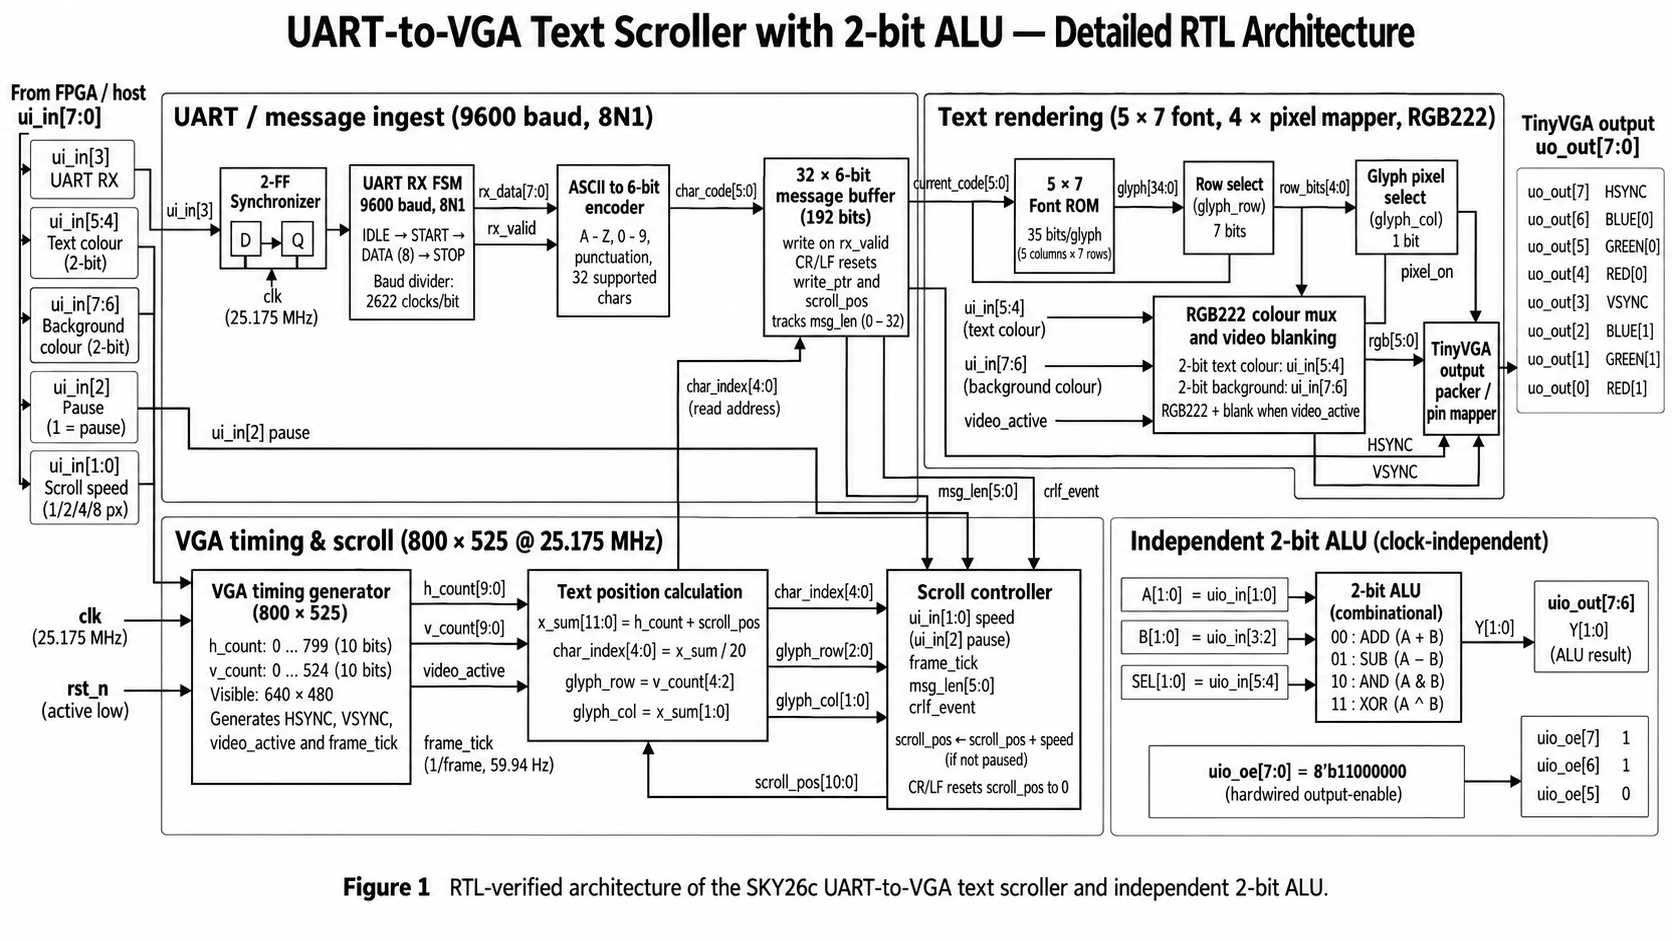

**Figure 1.** Functional architecture of the Tiny Tapeout SKY26c UART-to-VGA text scroller and independent 2-bit ALU.

**Architecture explanation.** The chip contains two separate signal-processing paths. The upper UART-to-VGA datapath accepts serial data on `ui_in[3]`, synchronizes it, decodes 8-N-1 UART frames at a nominal 9600 baud, and maps accepted characters to compact 6-bit codes. A 32-entry × 6-bit message store occupies **192 bits** of character-code storage. The current character is selected from the message store, and a **5 × 7** font ROM provides the glyph pattern used for 4×-scaled on-screen text.

**Raster and scrolling control.** An 800 × 525 timing generator driven by the nominal **25.175 MHz** clock provides the horizontal and vertical raster counters, video-active qualifier, negative-polarity HSYNC and VSYNC, and frame tick. The scroll state advances by **1, 2, 4, or 8 pixels per frame** according to `ui_in[1:0]` and can be paused with `ui_in[2]`. The current scroll position and pixel coordinates are used to select the character, glyph row, and glyph column. The selected glyph bit determines the foreground/background RGB222 colour, with blanking outside the active display region.

**Output interfaces.** The display path uses **`uo_out[7:0]`**; `uo_out[7]` carries HSYNC, `uo_out[3]` carries VSYNC, and the other six lines carry the two-bit red, green, and blue channels. Independently, the **combinational 2-bit ALU** receives `A`, `B`, and operation select from **`uio_in[5:0]`** and produces its 2-bit result on **`uio_out[7:6]`** (with `uio_oe = 8'b11000000`).

*Reading the figure:* This is a functional illustration; some inter-block wires are abstracted for readability, not a complete netlist. The unchanged, commit-pinned [Verilog RTL](https://github.com/nobleg30/ttsky26c-uart-vga-scroller) is the authoritative source for signal-level connectivity. The executable RTL tests later in this notebook independently verify major functional behavior.


## 2 · Fetch, freeze and inspect the original RTL (source of truth)

This notebook **clones** our publicly available Tiny Tapeout SKY26c project at execution time, using the specific **Git commit e097ce8db09eae269d17754536cfc714027c2f0c** to ensure reproducibility. The full commit hash and SHA-256 of `src/project.v` are printed and saved. No RTL is rewritten or replaced by an idealized example. A working internet connection is required at this one step.

**Independent repository evidence:** At that same source commit, the project's GitHub Actions reported **successful GDS, RTL test and documentation workflows on September 7, 2026** ([view CI history](https://github.com/nobleg30/ttsky26c-uart-vga-scroller/actions)). Those are historical upstream workflow statuses, **not** claims that the tests below have already run in this notebook.

In [2]:
PINNED_COMMIT = 'e097ce8db09eae269d17754536cfc714027c2f0c'  # Verified source revision: 2026-09-07.
if not RTL_ROOT.exists():
    print('Fetching original Tiny Tapeout repository...')
    cmd(['git','clone','--quiet','--depth','1',REPO_URL,str(RTL_ROOT)],timeout=120)
if PINNED_COMMIT:
    cmd(['git','fetch','--quiet','--depth','1','origin',PINNED_COMMIT],cwd=RTL_ROOT)
    cmd(['git','checkout','--quiet',PINNED_COMMIT],cwd=RTL_ROOT)
commit=cmd(['git','rev-parse','HEAD'],cwd=RTL_ROOT)
rtl_path=RTL_ROOT/'src'/'project.v'
rtl=rtl_path.read_text()
sha256=hashlib.sha256(rtl_path.read_bytes()).hexdigest()
assert TOP in rtl and 'module vga_timing' in rtl and 'module uart_rx' in rtl
print('Git commit :',commit)
print('RTL SHA256 :',sha256)
print('RTL lines  :',len(rtl.splitlines()))
print('Project top:',TOP)
source_record={'repository': REPO_URL,'commit':commit,'rtl_sha256':sha256}
(RESULTS/'source_provenance.json').write_text(json.dumps(source_record,indent=2))
display(pd.DataFrame([{'Setting':'Clock', 'Value':'25.175 MHz'},
                      {'Setting':'UART', 'Value':'9600, 8N1; divider 2622'},
                      {'Setting':'Message storage','Value':'32 × 6-bit = 192 bits'},
                      {'Setting':'Tiles','Value':'1 × 2'},
                      {'Setting':'Top module','Value':TOP}]))

Fetching original Tiny Tapeout repository...
Git commit : e097ce8db09eae269d17754536cfc714027c2f0c
RTL SHA256 : 278cfe02750b661d2953511f0262a854b13750ccc4c1306dbcefb3263b82bfdb
RTL lines  : 1186
Project top: tt_um_nobleg30_uart_vga_scroller


,Setting,Value
0,Clock,25.175 MHz
1,UART,"9600, 8N1; divider 2622"
2,Message storage,32 × 6-bit = 192 bits
3,Tiles,1 × 2
4,Top module,tt_um_nobleg30_uart_vga_scroller


## 3 · Timing as an engineering constraint, not a screenshot

**VGA.** The RTL implements 640 active pixels in an 800-pixel line (16-pixel front porch, 96-pixel negative HSYNC, 48-pixel back porch) and 480 active lines in a 525-line frame (10-line front porch, 2-line negative VSYNC, 33-line back porch). This produces approximately 59.94 frames/s at 25.175 MHz.

**UART.** The RTL uses an integer clock divider of 2622, not an ideal fractional 9600-baud clock. Measuring that difference checks the selected design's actual timing.

Pixel period: 39.7219 ns | Line period: 31.778 us
Frame rate: 59.94048 Hz | UART realized rate: 9601.449 baud
UART baud error: +0.0151%


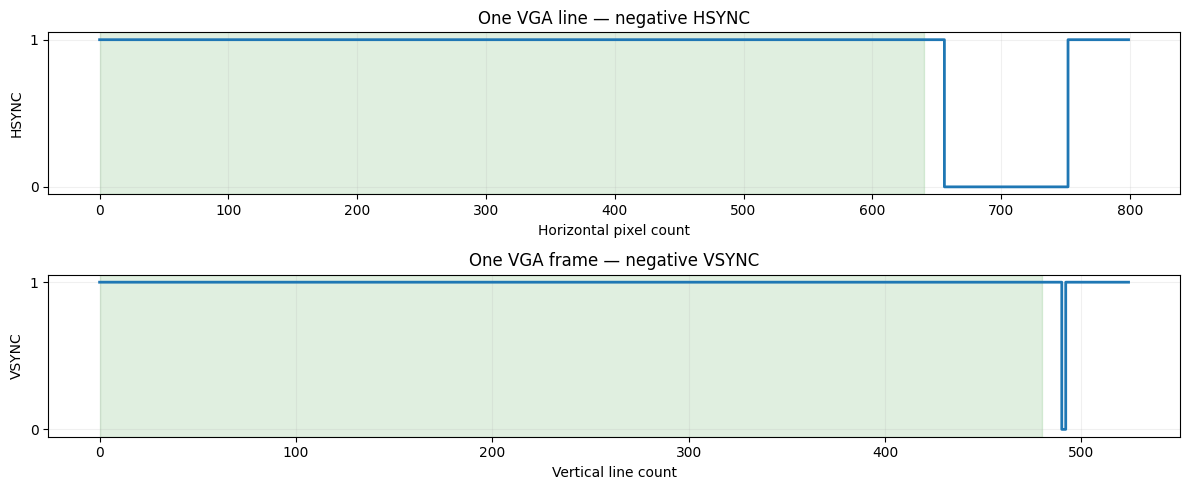

In [3]:
H_ACTIVE,H_FRONT,H_SYNC,H_BACK=640,16,96,48
V_ACTIVE,V_FRONT,V_SYNC,V_BACK=480,10,2,33
H_TOTAL=H_ACTIVE+H_FRONT+H_SYNC+H_BACK
V_TOTAL=V_ACTIVE+V_FRONT+V_SYNC+V_BACK
actual_baud=FCLK/UART_DIVISOR
frame_rate=FCLK/(H_TOTAL*V_TOTAL)
assert (H_TOTAL,V_TOTAL)==(800,525)
print(f'Pixel period: {1e9/FCLK:.4f} ns | Line period: {H_TOTAL/FCLK*1e6:.3f} us')
print(f'Frame rate: {frame_rate:.5f} Hz | UART realized rate: {actual_baud:.3f} baud')
print(f'UART baud error: {(actual_baud/9600-1)*100:+.4f}%')
fig, axs=plt.subplots(2,1,figsize=(12,5),sharex=False)
x=np.arange(H_TOTAL); y=np.arange(V_TOTAL)
hs=~((x>=656)&(x<752)); vs=~((y>=490)&(y<492))
axs[0].step(x,hs.astype(int),where='post',lw=2); axs[0].axvspan(0,640,alpha=.12,color='green'); axs[0].set(xlabel='Horizontal pixel count',ylabel='HSYNC',title='One VGA line — negative HSYNC'); axs[0].set_yticks([0,1]); axs[0].grid(alpha=.18)
axs[1].step(y,vs.astype(int),where='post',lw=2); axs[1].axvspan(0,480,alpha=.12,color='green'); axs[1].set(xlabel='Vertical line count',ylabel='VSYNC',title='One VGA frame — negative VSYNC'); axs[1].set_yticks([0,1]); axs[1].grid(alpha=.18)
plt.tight_layout();plt.savefig(RESULTS/'vga_timing_reference.png',dpi=150);plt.show()

### Experiment A · An 8-N-1 UART frame at a real integer divisor

For every character there is one low start bit, eight LSB-first payload bits, and one high stop bit. At 9600 baud a 10-bit frame takes about 1.0417 ms. Select another 8-bit character to inspect its waveform; unlike a photograph, this figure is generated algorithmically.

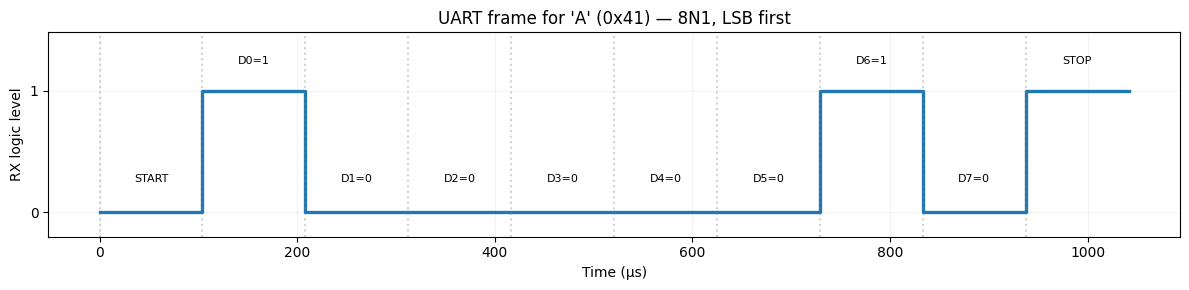

In [4]:
UART_EXAMPLE = 'A'  # edit and rerun; any single 8-bit ASCII character
assert len(UART_EXAMPLE)==1 and ord(UART_EXAMPLE)<128
value=ord(UART_EXAMPLE)
bits=[0]+[(value>>b)&1 for b in range(8)]+[1]
labels=['START']+[f'D{i}={bits[i+1]}' for i in range(8)]+['STOP']
t=np.arange(11)*UART_DIVISOR/FCLK*1e6
fig,ax=plt.subplots(figsize=(12,3))
ax.step(t, bits+[1],where='post',lw=2.4)
for i,label in enumerate(labels):
    ax.axvline(t[i],color='grey',ls=':',alpha=.35)
    ax.text((t[i]+t[i+1])/2, 1.22 if bits[i] else .25, label,ha='center',fontsize=8)
ax.set(xlabel='Time (µs)',ylabel='RX logic level',ylim=(-.2,1.48),title=f'UART frame for {UART_EXAMPLE!r} (0x{value:02X}) — 8N1, LSB first')
ax.set_yticks([0,1]);ax.grid(alpha=.15)
plt.tight_layout();plt.savefig(RESULTS/'uart_frame_reference.png',dpi=150);plt.show()

## 4 · Pixel rendering driven by the **actual Verilog font ROM**

Rather than substituting a generic Python font, the following code **parses the 35-bit glyph tables in `project.v`**. This makes the Python visualization source-linked. Character codes are compact: SPACE=0, A–Z=1–26, 0–9=27–36, `. -=!? :` occupy 37–41. Supported lowercase input is converted to uppercase by the UART write logic; unsupported printable ASCII becomes a space.

Note the **actual vertical window** is lines 224–255. There is a 4-pixel left margin per 32×32 cell. For each glyph, five columns occupy 20 pixels and seven rows occupy 28 pixels.

Parsed 42 glyphs directly from the RTL. A(1) bitmap:
·███·
█···█
█···█
█████
█···█
█···█
█···█


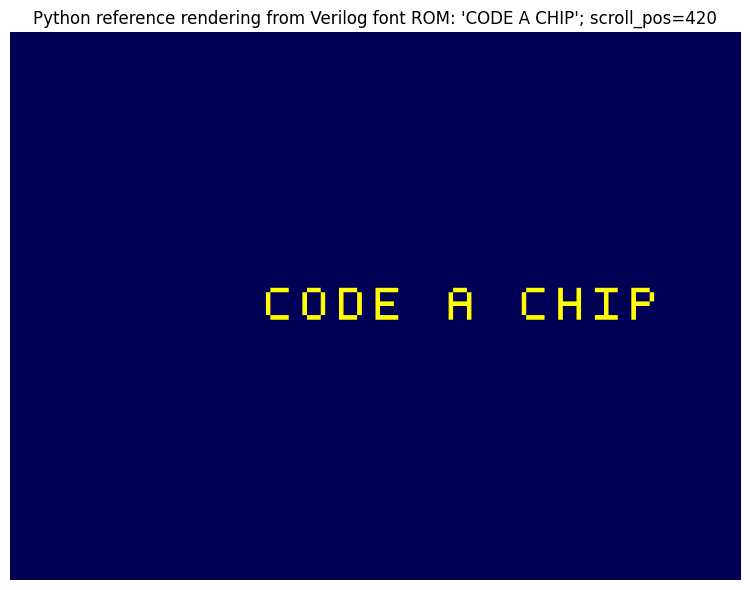

In [5]:
font_entries=re.findall(r"6'd(\d+)\s*:\s*glyph35\s*=\s*35'b([01_]+)\s*;",rtl)
FONT_ROM={int(code):np.array([int(c) for c in binary.replace('_','')],dtype=np.uint8).reshape(7,5)
          for code,binary in font_entries}
assert len(FONT_ROM)>=42, f'Unexpected font table: only {len(FONT_ROM)} glyphs parsed'
assert FONT_ROM[0].sum()==0
print(f'Parsed {len(FONT_ROM)} glyphs directly from the RTL. A(1) bitmap:')
print('\n'.join(''.join('█' if b else '·' for b in row) for row in FONT_ROM[1]))

def ascii_to_code_py(ch):
    z=ord(ch)
    if 65<=z<=90:return z-64
    if 97<=z<=122:return z-96
    if 48<=z<=57:return z-21
    return {32:0,46:37,45:38,33:39,63:40,58:41}.get(z,0)

assert [ascii_to_code_py(ch) for ch in 'Az09!?'] == [1,26,27,36,39,40]
TEXT_COLORS=[(3,3,3),(3,3,0),(0,3,3),(3,0,3)]
BG_COLORS=[(0,0,0),(0,0,1),(0,1,0),(1,0,0)]

def reference_frame(message,scroll_pos=400,text_choice=0,bg_choice=0):
    """Source-linked reference model; pixels are NOT output of an RTL simulator."""
    frame=np.empty((480,640,3),dtype=np.uint8)
    frame[:]=np.array(BG_COLORS[bg_choice],dtype=np.uint8)*85
    fg=np.array(TEXT_COLORS[text_choice],dtype=np.uint8)*85
    msg=message[:32]
    for index,ch in enumerate(msg):
        glyph=FONT_ROM[ascii_to_code_py(ch)]
        x0=640-scroll_pos+index*32+4
        for gy in range(7):
            for gx in range(5):
                if glyph[gy,gx]:
                    xa,xb=x0+4*gx,x0+4*gx+4
                    ya,yb=224+4*gy,228+4*gy
                    if xb>0 and xa<640:
                        frame[ya:yb,max(0,xa):min(640,xb)]=fg
    return frame

MESSAGE='CODE A CHIP'        # editable; supported glyphs listed above
SCROLL_POSITION=420          # 0..(640 + 32*len(MESSAGE)-1)
TEXT_CHOICE=1                # 0 white,1 yellow,2 cyan,3 magenta
BACKGROUND_CHOICE=1         # 0 black,1 dark blue,2 dark green,3 dark red
assert 0<len(MESSAGE)<=32
frame=reference_frame(MESSAGE,SCROLL_POSITION,TEXT_CHOICE,BACKGROUND_CHOICE)
plt.figure(figsize=(13,6));plt.imshow(frame);plt.axis('off')
plt.title(f'Python reference rendering from Verilog font ROM: {MESSAGE!r}; scroll_pos={SCROLL_POSITION}')
plt.tight_layout();plt.savefig(RESULTS/'vga_python_reference.png',dpi=120);plt.show()

### Experiment B · Scroll-rate tradeoff and message width

In hardware, `scroll_step = 1 << ui_in[1:0]`, advancing on **frame_tick** while unpaused and while `msg_len ≠ 0`. Position wraps when the next increment reaches `640 + 32 × msg_len`. This experiment explores **all four speeds** and why the message length, not the screen width alone, determines traversal time.

,ui_in[1:0],Pixels/frame,Approx. frames/wrap,Approx. seconds/wrap
0,00,1,992,16.549752
1,01,2,496,8.274876
2,10,4,248,4.137438
3,11,8,124,2.068719


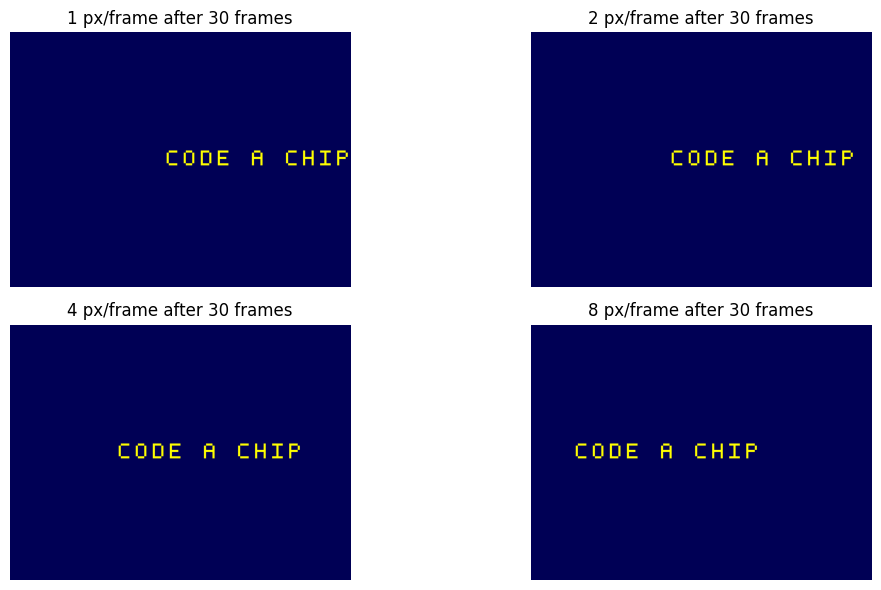

For a maximum-length 32-character message: 640 + 32×32 = 1664 pixels; storage = 32×6 = 192 bits


In [6]:
msg_length=min(len(MESSAGE),32)
scroll_limit=640+32*msg_length
speeds=[1,2,4,8]
steps_to_wrap=[math.ceil(scroll_limit/s) for s in speeds]
df_speed=pd.DataFrame({'ui_in[1:0]':['00','01','10','11'],
                        'Pixels/frame':speeds,
                        'Approx. frames/wrap':steps_to_wrap,
                        'Approx. seconds/wrap':[k/frame_rate for k in steps_to_wrap]})
display(df_speed)
fig,axs=plt.subplots(2,2,figsize=(12,6))
for ax,step in zip(axs.flat,speeds):
    ax.imshow(reference_frame(MESSAGE,min(320+step*30,scroll_limit-1),TEXT_CHOICE,BACKGROUND_CHOICE))
    ax.set_title(f'{step} px/frame after 30 frames');ax.axis('off')
plt.tight_layout();plt.savefig(RESULTS/'scroll_experiment.png',dpi=135);plt.show()
print('For a maximum-length 32-character message: 640 + 32×32 =',640+32*32,'pixels; storage = 32×6 = 192 bits')

### Live laboratory · Change the message, frame position, colour and scroll speed

The optional controls below generate images from the original **Verilog font ROM**, not from a generic system font. The image is a **Python reference render** (not a captured RTL output). The position slider represents the registered `scroll_pos`. The speed control previews how far that position advances after a chosen number of frames. It works in Colab with the widget manager enabled.

In [7]:
try:
    import ipywidgets as widgets
    from IPython.display import clear_output
    if 'google.colab' in sys.modules:
        from google.colab import output
        output.enable_custom_widget_manager()
    message_widget = widgets.Text(value='CODE A CHIP', description='Text:', layout=widgets.Layout(width='410px'))
    scroll_widget = widgets.IntSlider(value=380,min=0,max=1600,step=4,description='Start position:',continuous_update=False)
    speed_widget = widgets.Dropdown(options=[('1 px/frame',1),('2 px/frame',2),('4 px/frame',4),('8 px/frame',8)],value=2,description='Speed:')
    frames_widget = widgets.IntSlider(value=20,min=0,max=100,step=5,description='Frames:',continuous_update=False)
    fg_widget = widgets.Dropdown(options=[('White',0),('Yellow',1),('Cyan',2),('Magenta',3)],value=1,description='Text RGB:')
    bg_widget = widgets.Dropdown(options=[('Black',0),('Dark blue',1),('Dark green',2),('Dark red',3)],value=1,description='Background:')
    pane=widgets.Output()
    def redraw(*_):
        msg=message_widget.value[:32]
        if len(msg)==0: msg=' '
        limit=640+32*len(msg)
        pos=(scroll_widget.value+speed_widget.value*frames_widget.value)%limit
        with pane:
            clear_output(wait=True)
            print(f'Stored characters: {len(msg)}/32 | position: {pos}/{limit} | 2-bit palette choices')
            fig,ax=plt.subplots(figsize=(11,4.7))
            ax.imshow(reference_frame(msg,pos,fg_widget.value,bg_widget.value))
            ax.axis('off');plt.show();plt.close(fig)
    for control in [message_widget,scroll_widget,speed_widget,frames_widget,fg_widget,bg_widget]:
        control.observe(redraw,names='value')
    display(widgets.VBox([message_widget, widgets.HBox([scroll_widget,speed_widget]),
                          widgets.HBox([frames_widget,fg_widget,bg_widget]),pane]))
    redraw()
except ImportError:
    print('ipywidgets is optional. Edit MESSAGE and rendering parameters in the preceding cell instead.')


## 5 · Build the actual RTL simulator (Icarus Verilog)

The next tests are **not** Python guesses: they compile and simulate the original `src/project.v` with `iverilog`/`vvp`. They deliberately use small independent SystemVerilog testbenches generated by this notebook, allowing the reviewer to inspect stimuli and check outputs.

**Set-up:** The next cell installs Icarus on Colab's Debian/Ubuntu runtime if not already installed. The initial install requires internet.

In [8]:
if shutil.which('iverilog') is None:
    if not shutil.which('apt-get'):
        raise RuntimeError('Icarus Verilog not installed. Install iverilog and vvp, then rerun this cell.')
    print('Installing open-source Icarus Verilog...')
    cmd(['apt-get','update','-qq'],timeout=240)
    cmd(['apt-get','install','-y','-qq','iverilog'],timeout=240)
print('Icarus:',cmd(['iverilog','-V']).splitlines()[0])

def simulate_tb(name,source,timeout=240):
    tb_path=RESULTS/f'{name}.sv'; tb_path.write_text(source)
    compiled=RESULTS/f'{name}.vvp'
    print('Compiling RTL with:',rtl_path)
    cmd(['iverilog','-g2012','-s',f'tb_{name}','-o',str(compiled),str(rtl_path),str(tb_path)])
    output=cmd(['vvp',str(compiled)],timeout=timeout)
    (RESULTS/f'{name}.log').write_text(output+'\n')
    if 'RTL_PASS' not in output:
        raise AssertionError(f'No PASS marker for {name}:\n{output[-3000:]}')
    print(output[-1800:]);return output

Installing open-source Icarus Verilog...
Icarus: Icarus Verilog version 12.0 (stable) ()


### Experiment C · Exhaustive verification of all 64 ALU input combinations

For each `SEL` and all 16 `A, B` pairs, compare the real RTL outputs against an independently computed modulo-4 model. Check `uio_oe == 8'hC0` and that non-output bits remain zero. This checks actual encoded pin behavior, not a second ALU written in Python.

In [9]:
alu_testbench=r"""
`timescale 1ns/1ps
module tb_alu;
  reg clk=0, rst_n=0, ena=1;
  // Start with a nonzero vector: the first test vector is zero.
  // This guarantees an input transition to trigger always @* in Icarus.
  reg [7:0] ui_in=8'h08, uio_in=8'h3F;
  wire [7:0] uo_out,uio_out,uio_oe;
  integer a,b,sel,expect_y,got_y,count=0;
  tt_um_nobleg30_uart_vga_scroller dut(
    .ui_in(ui_in),.uo_out(uo_out),.uio_in(uio_in),.uio_out(uio_out),.uio_oe(uio_oe),
    .ena(ena),.clk(clk),.rst_n(rst_n));
  initial begin
    #5;
    if (uio_oe !== 8'hC0) $fatal(1,"Wrong uio_oe");
    for(sel=0;sel<4;sel=sel+1)
      for(b=0;b<4;b=b+1)
        for(a=0;a<4;a=a+1) begin
          uio_in=a|(b<<2)|(sel<<4);
          #5;
          case(sel)
           0: expect_y=(a+b)&3;
           1: expect_y=(a-b)&3;
           2: expect_y=a&b;
           default:expect_y=a^b;
          endcase
          got_y=(uio_out>>6)&3;
          if (got_y !== expect_y || uio_out[5:0] !== 6'b000000)
            $fatal(1,"Mismatch A=%0d B=%0d SEL=%0d got=%0d expected=%0d",a,b,sel,got_y,expect_y);
          count=count+1;
        end
    $display("RTL_PASS: ALU checked %0d/64 patterns; output-enable 0x%02h",count,uio_oe);
    $finish;
  end
endmodule
"""
alu_log=simulate_tb('alu',alu_testbench)
assert '64/64' in alu_log

Compiling RTL with: /content/ttsky26c-uart-vga-scroller/src/project.v
RTL_PASS: ALU checked 64/64 patterns; output-enable 0xc0
/content/code_a_chip_results/alu.sv:33: $finish called at 325000 (1ps)


### Experiment D · Verify an entire 800 × 525 VGA frame in RTL

Test **420,000 consecutive pixels** at the real RTL `vga_timing` submodule interface. Check the active-video window, sync polarities, total low-pulse counts, and that frame_tick occurs once at `(799,524)`. The test also checks horizontal and vertical counter sequencing pixel by pixel. It therefore provides stronger evidence than sampling a few oscilloscope points.

In [10]:
vga_tb=r"""
`timescale 1ns/1ps
module tb_vga;
  reg clk=0,rst_n=0;
  wire [9:0] h_count,v_count;
  wire hsync,vsync,video_active,frame_tick;
  integer i,ex_h,ex_v,n_active=0,n_hlow=0,n_vlow=0,n_tick=0;
  vga_timing dut(.clk(clk),.rst_n(rst_n),.h_count(h_count),.v_count(v_count),
   .hsync(hsync),.vsync(vsync),.video_active(video_active),.frame_tick(frame_tick));
  always #5 clk=~clk;
  initial begin
    repeat (3) @(negedge clk);
    rst_n=1;
    for(i=0;i<420000;i=i+1) begin
      ex_h=i%800;ex_v=i/800;
      #1;
      if(h_count !== ex_h || v_count !== ex_v)
        $fatal(1,"Counters: cycle=%0d got (%0d,%0d) expected (%0d,%0d)",i,h_count,v_count,ex_h,ex_v);
      if(hsync !== !((ex_h>=656)&&(ex_h<752))) $fatal(1,"HSYNC at %0d",i);
      if(vsync !== !((ex_v>=490)&&(ex_v<492))) $fatal(1,"VSYNC at %0d",i);
      if(video_active !== ((ex_h<640)&&(ex_v<480))) $fatal(1,"Active at %0d",i);
      if(frame_tick !== ((ex_h==799)&&(ex_v==524))) $fatal(1,"Tick at %0d",i);
      if(video_active) n_active=n_active+1;
      if(!hsync) n_hlow=n_hlow+1;
      if(!vsync) n_vlow=n_vlow+1;
      if(frame_tick) n_tick=n_tick+1;
      @(posedge clk); #1;
    end
    if(n_active!=307200 || n_hlow!=50400 || n_vlow!=1600 || n_tick!=1)
       $fatal(1,"Wrong counts active=%0d Hlow=%0d Vlow=%0d ticks=%0d",n_active,n_hlow,n_vlow,n_tick);
    if(h_count!==0 || v_count!==0) $fatal(1,"Frame wrap failed");
    $display("RTL_PASS: VGA 420000 pixels, active=%0d, Hlow=%0d, Vlow=%0d, ticks=%0d",n_active,n_hlow,n_vlow,n_tick);
    $finish;
  end
endmodule
"""
vga_log=simulate_tb('vga',vga_tb,timeout=240)
assert '420000 pixels' in vga_log

Compiling RTL with: /content/ttsky26c-uart-vga-scroller/src/project.v
RTL_PASS: VGA 420000 pixels, active=307200, Hlow=50400, Vlow=1600, ticks=1
/content/code_a_chip_results/vga.sv:33: $finish called at 4200026000 (1ps)


### Experiment E · Send real UART waveforms to RTL and inspect 6-bit storage

A UART byte lasts 10×2622 clock cycles. We send `A`, lowercase `b`, and `?` to the *actual* chip top module, then check the stored compact codes **1, 2, 40**. Finally, carriage return (CR) must reset the **write pointer and scroll position**, but **must not clear `msg_len`**. This is a deliberate subtlety in the RTL, useful for students to learn the difference between a restart command and a buffer-clear command.

In [11]:
uart_tb=r"""
`timescale 1ns/1ps
module tb_uart;
  reg clk=0,rst_n=0,ena=1;
  reg [7:0] ui_in=8'h08,uio_in=0;
  wire [7:0] uo_out,uio_out,uio_oe;
  tt_um_nobleg30_uart_vga_scroller dut(
    .ui_in(ui_in),.uo_out(uo_out),.uio_in(uio_in),.uio_out(uio_out),.uio_oe(uio_oe),
    .ena(ena),.clk(clk),.rst_n(rst_n));
  always #5 clk=~clk;
  task send_byte(input [7:0] value);
    integer k;
    begin
       ui_in[3]=0;repeat(2622) @(negedge clk);
       for(k=0;k<8;k=k+1) begin
         ui_in[3]=value[k]; repeat(2622) @(negedge clk);
       end
       ui_in[3]=1;repeat(2622) @(negedge clk);
       repeat(8) @(negedge clk);
    end
  endtask
  initial begin
    repeat(8) @(negedge clk);
    rst_n=1;
    send_byte(8'h41);  // 'A' -> 1
    send_byte(8'h62);  // 'b' -> 2
    send_byte(8'h3F);  // '?' -> 40
    if(dut.msg_len !== 3 || dut.write_ptr !== 3 ||
       dut.msg_mem[0] !== 1 || dut.msg_mem[1] !== 2 || dut.msg_mem[2] !== 40)
       $fatal(1,"UART buffer: len=%0d ptr=%0d mem=%0d,%0d,%0d",dut.msg_len,dut.write_ptr,dut.msg_mem[0],dut.msg_mem[1],dut.msg_mem[2]);
    send_byte(8'h0D); // Carriage return
    if(dut.msg_len !== 3 || dut.write_ptr !== 0 || dut.scroll_pos !== 0)
      $fatal(1,"CR semantics wrong: len=%0d ptr=%0d scroll=%0d",dut.msg_len,dut.write_ptr,dut.scroll_pos);
    $display("RTL_PASS: UART bytes A,b,? stored 1,2,40; CR restarts pointer without clearing msg_len");
    $finish;
  end
endmodule
"""
uart_log=simulate_tb('uart',uart_tb,timeout=240)
assert 'A,b,?' in uart_log

Compiling RTL with: /content/ttsky26c-uart-vga-scroller/src/project.v
RTL_PASS: UART bytes A,b,? stored 1,2,40; CR restarts pointer without clearing msg_len
/content/code_a_chip_results/uart.sv:35: $finish called at 1049200000 (1ps)


## 6 · Design-space exploration: representation, bandwidth and area reasoning

This analysis is **analytical**, not a synthesis or silicon power measurement. A full framebuffer at RGB222 needs `640×480×6 = 1,843,200` bits (ignoring overhead); the **character buffer** is `32×6 = 192` bits. The reduction factor describes only *framebuffer versus character-storage bits*, not total-chip area, because font ROM logic, counters, registers and routing also consume silicon.

,Representation,Storage bits,Ki bits
0,Full 640×480 RGB222 framebuffer,1843200,1800.0000
1,"32-character, 6-bit code memory",192,0.1875


Character-memory / framebuffer storage reduction: 9,600× (memory bits only)


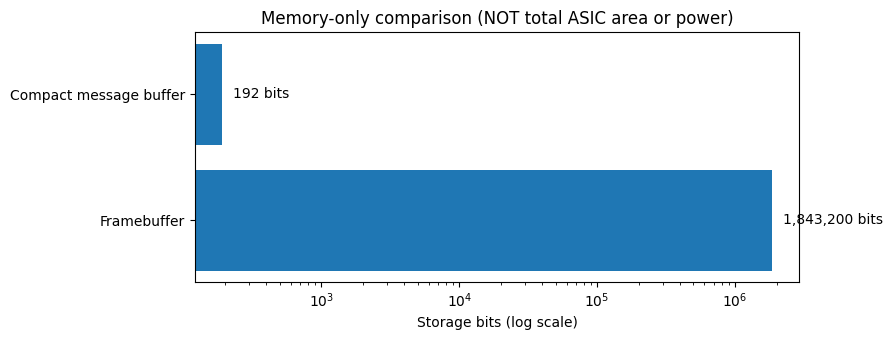

In [12]:
frame_bits=640*480*6
char_bits=32*6
comparison=pd.DataFrame([
 {'Representation':'Full 640×480 RGB222 framebuffer','Storage bits':frame_bits},
 {'Representation':'32-character, 6-bit code memory','Storage bits':char_bits},
])
comparison['Ki bits']=comparison['Storage bits']/1024
display(comparison)
print(f'Character-memory / framebuffer storage reduction: {frame_bits/char_bits:,.0f}× (memory bits only)')
assert frame_bits==1_843_200 and char_bits==192
fig,ax=plt.subplots(figsize=(9,3.5))
ax.barh(['Framebuffer','Compact message buffer'],[frame_bits,char_bits]);ax.set_xscale('log');ax.set_xlabel('Storage bits (log scale)');ax.set_title('Memory-only comparison (NOT total ASIC area or power)')
for y,val in enumerate([frame_bits,char_bits]):ax.text(val*1.2,y,f'{val:,} bits',va='center')
plt.tight_layout();plt.savefig(RESULTS/'memory_comparison.png',dpi=150);plt.show()

## 7 · Physical design: evidence and boundaries

![Original SKY26c project routed physical-design render (Tiny Tapeout published asset)](https://raw.githubusercontent.com/TinyTapeout/tinytapeout-project-renders/main/shuttles/ttsky26c/tt_um_nobleg30_uart_vga_scroller/render.png)

*Figure: the actual physical-design render published for Tiny Tapeout SKY26c #847 (source: Tiny Tapeout project-renders repository).*

The original open-source project is published on Tiny Tapeout SKY26c and links to an **interactive OASIS physical-layout viewer**. The existing project uses the SKY130 open-source PDK and a Tiny Tapeout flow built around LibreLane. The **published chip page provides design imagery and a layout-viewer link**, not a substitute for locally checked post-route quantitative metrics.

- [Published Tiny Tapeout chip page and design render](https://tinytapeout.com/chips/ttsky26c/tt_um_nobleg30_uart_vga_scroller)
- [Open the real published OASIS layout in Tiny Tapeout Explorer](https://gds-explorer.tinytapeout.com/viewer?file=https%3A%2F%2Fshuttle-assets.tinytapeout.com%2Fttsky26c%2Ftt_um_nobleg30_uart_vga_scroller%2Ftt_um_nobleg30_uart_vga_scroller.oas&pdk=sky130A)
- [Original GitHub Actions (RTL checks and ASIC flow artifacts)](https://github.com/nobleg30/ttsky26c-uart-vga-scroller/actions)

**For review**: open the linked viewer to inspect standard-cell geometry and routing. If quantitative reports are available in the original LibreLane artifact, add the exact **commit-matched** cell area, cell count, slack, density, DRC, and LVS numbers with a link to the log. Do **not** infer die area or measured power from tile count alone.

## 8 · Experiment F — Run the original Tiny Tapeout Cocotb integration regression

This test is taken from the **unchanged source repository**, not written to fit the new testbench. It exercises UART reception of a 32-character message, scrolling/pause, colour selection, the 2-bit ALU, and selected output pixel comparisons. The original regression also writes two **RTL-captured** VGA frame images to `test/output/`. The entire test is a single Cocotb test case with several internal assertions—not a claim of multiple independent Cocotb test cases.

The notebook uses `test/requirements.txt` (Cocotb 2.0.1 and pytest 8.4.2) plus the original `test/Makefile`, with Icarus in **RTL simulation** mode (`GATES` is not enabled). The first three RTL experiments remain separate and are useful for isolated checks. A clean run of this fourth check increases coverage beyond isolated unit-style assertions.

**Execution policy:** `RUN_ORIGINAL_COCOTB = True` by default. If you disable it to save time, the final manifest records **SKIPPED**, never PASS; re-enable and run it before finalizing your award submission. Only results actually produced in the current session are counted.

RTL_PASS: Original Cocotb integrated regression: TESTS=1 PASS=1 FAIL=0 SKIP=0
Source of truth: test/test.py and test/Makefile at commit e097ce8db09eae269d17754536cfc714027c2f0c
Selected final log lines:
 0.00ns INFO     cocotb                             Running on Icarus Verilog version 12.0 (stable)
     0.00ns INFO     cocotb                             Seeding Python random module with 1793436884
     0.00ns INFO     cocotb                             Initialized cocotb v2.0.1 from /usr/local/lib/python3.13/dist-packages/cocotb
     0.00ns INFO     cocotb                             Running tests
     0.00ns INFO     cocotb.regression                  running test.test_uart_vga_scroller_4x_colour (1/1)
34424764.90ns INFO     cocotb.tb                          Verified and saved output/vga_32char_white_black_start.png
34450369.90ns INFO     cocotb.tb                          Verified and saved output/vga_32char_yellow_blue_end.png
34450369.90ns INFO     cocotb.tb                    

**Captured RTL output: white text on black**

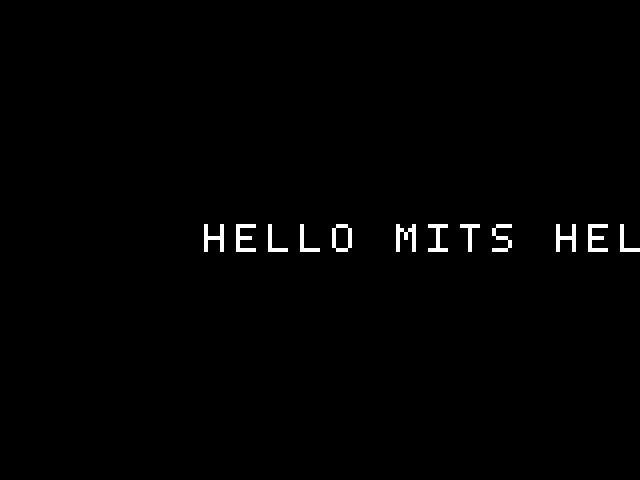

**Captured RTL output: yellow text on blue**

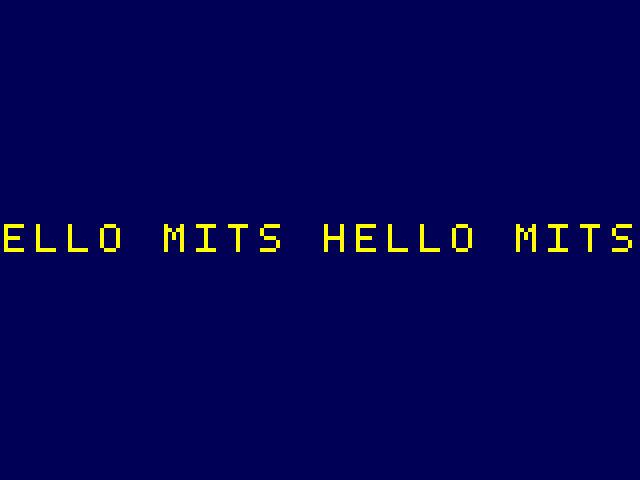

Cocotb frames preserved: 2 / 2


In [13]:
RUN_ORIGINAL_COCOTB = True   # Default: run the complete original Cocotb RTL regression.
cocotb_status = 'SKIPPED'
cocotb_summary = None
cocotb_frame_paths = []

if RUN_ORIGINAL_COCOTB:
    # Install only into the present Colab/runtime environment. No git push or remote mutation.
    cmd([sys.executable, '-m', 'pip', 'install', '-q',
         '-r', str(RTL_ROOT / 'test' / 'requirements.txt')], timeout=300)
    full_out = cmd(['make', 'SIM=icarus'], cwd=RTL_ROOT / 'test', timeout=900)
    (RESULTS / 'original_cocotb.log').write_text(full_out)

    # Verify the printed test summary rather than assuming return code alone is enough.
    report = re.search(r'TESTS\s*=\s*(\d+)\s+PASS\s*=\s*(\d+)\s+FAIL\s*=\s*(\d+)\s+SKIP\s*=\s*(\d+)', full_out)
    if report is None:
        raise AssertionError('Original regression completed but the Cocotb test summary could not be parsed. Inspect original_cocotb.log.')
    n_tests, n_pass, n_fail, n_skip = map(int, report.groups())
    if not (n_tests >= 1 and n_pass == n_tests and n_fail == 0 and n_skip == 0):
        raise AssertionError(f'Cocotb regression not fully passing: {report.group(0)}')
    cocotb_status = 'PASS'
    cocotb_summary = {'total': n_tests, 'passed': n_pass, 'failed': n_fail, 'skipped': n_skip}
    print('RTL_PASS: Original Cocotb integrated regression:', report.group(0))
    print('Source of truth: test/test.py and test/Makefile at commit', commit)
    print('Selected final log lines:')
    print(full_out[-2200:])

    # Preserve and display the *actual* Verilog/Cocotb-generated images.
    # These are distinct from the earlier Python font-ROM visualization.
    from IPython.display import Image as NotebookImage
    frame_dir = RESULTS / 'rtl_cocotb_frames'
    frame_dir.mkdir(parents=True, exist_ok=True)
    for name, caption in [
        ('vga_32char_white_black_start.png', 'Captured RTL output: white text on black'),
        ('vga_32char_yellow_blue_end.png', 'Captured RTL output: yellow text on blue')
    ]:
        generated = RTL_ROOT / 'test' / 'output' / name
        if generated.exists():
            preserved = frame_dir / name
            shutil.copy2(generated, preserved)
            cocotb_frame_paths.append(str(preserved))
            display(Markdown('**' + caption + '**'))
            display(NotebookImage(filename=str(preserved)))
        else:
            print('NOTE: generated frame not found:', generated)
    print('Cocotb frames preserved:', len(cocotb_frame_paths), '/ 2')
else:
    print('Original Cocotb regression was SKIPPED in this session; no pass is claimed.')

## 9 · Consolidated four-check validation and reproducibility manifest

The next cell records the **actual current-session** results: exhaustive 64-vector ALU RTL verification, 420,000 VGA timing pixels, UART reception/CR behavior, and the original integrated Cocotb test. The first three are independent notebook-generated SystemVerilog tests; the fourth is the original repository's Cocotb regression. The results do **not** imply post-silicon verification.

**Coverage limits:** The full VGA-timing sweep checks synchronization, active-video window and frame boundary—not RGB correctness for all 307,200 active display locations. The integrated Cocotb suite verifies selected pixel outputs and captures output images; the earlier interactive renderer is a Python **reference** image derived from the RTL font, not a captured chip image. The 9,600× memory figure concerns **storage bits only**, not full-chip power, performance or area.

In [14]:
validation = {
    'design': TOP,
    'original_tinytapeout_project': CHIP_URL,
    'source_repository': REPO_URL,
    'source_commit': commit,
    'rtl_sha256': sha256,
    'tool': {'rtl_simulator': (cmd(['iverilog', '-V']).splitlines()[0] if shutil.which('iverilog') else 'missing'),
             'cocotb': 'pinned by original test/requirements.txt to 2.0.1'},
    'tests': {
        'ALU_exhaustive_64_vectors': 'PASS' if '64/64' in alu_log else 'FAIL',
        'VGA_timing_full_frame_420000_cycles': 'PASS' if '420000 pixels' in vga_log else 'FAIL',
        'UART_three_bytes_and_CR': 'PASS' if 'A,b,?' in uart_log else 'FAIL',
        'Original_Cocotb_integrated_regression': cocotb_status,
    },
    'cocotb_test_counts': cocotb_summary,
    'cocotb_rtl_frame_capture_files': cocotb_frame_paths,
    'derived_metrics': {
        'clock_hz': FCLK,
        'frame_rate_hz': round(frame_rate, 6),
        'uart_realized_baud': round(actual_baud, 6),
        'message_storage_bits': 192,
        'framebuffer_storage_bits': frame_bits,
    },
    'limitations': 'Pre-silicon source-linked RTL simulations and analytical/reference visualizations; no measured silicon PPA',
}
assert all(result == 'PASS' for result in validation['tests'].values()), 'Not all four verification experiments passed in this execution.'
manifest_path = RESULTS / 'validation_manifest.json'
manifest_path.write_text(json.dumps(validation, indent=2))
display(pd.DataFrame([{'Verification': k, 'Result': v} for k, v in validation['tests'].items()]))
print('4/4 VERIFICATION CATEGORIES PASSED (original Cocotb has', cocotb_summary['total'], 'test case).')
print('Pinned RTL revision:', commit)
print('Validation manifest saved:', manifest_path)

,Verification,Result
0,ALU_exhaustive_64_vectors,PASS
1,VGA_timing_full_frame_420000_cycles,PASS
2,UART_three_bytes_and_CR,PASS
3,Original_Cocotb_integrated_regression,PASS


4/4 VERIFICATION CATEGORIES PASSED (original Cocotb has 1 test case).
Pinned RTL revision: e097ce8db09eae269d17754536cfc714027c2f0c
Validation manifest saved: /content/code_a_chip_results/validation_manifest.json


## 10 · Results export, discussion, and conclusions

**Results preservation.** The architecture is embedded directly in the Markdown cell in Section 1 and is also supplied as a standalone PNG in the submission package. The generated `code_a_chip_results/` directory contains logs for three independent RTL simulations and the original Cocotb regression, two actual Cocotb-generated VGA images (if produced), and a machine-readable source-linked validation summary. The following cell bundles these files without modifying the original GitHub repository.

**What was demonstrated:** A reproducible source-linked open-source digital ASIC educational workflow, using RTL simulation and real published layout evidence. A compact 32×6-bit character memory avoids a large raster framebuffer by generating visible glyph pixels on demand. Full-frame timing checks and independent integrated regression reduce the risk of presenting an unverified visualization as circuit behavior.

**Design boundaries and future exercises:** The font and colour choices are intentionally limited. UART baud-rate error follows from a fixed integer clock divider. The calculated character-memory advantage is **not** a synthesized area or power reduction. No post-route area/power/timing figures or silicon measurements are asserted without matching implementation reports. Suggested extensions include comparing UART divisors, defining CR/clear-message behavior, adding a source-matched timing/area report extractor, and expanding integration-coverage assertions.

### References

1. Noble G, [UART VGA Text Scroller with 2-bit ALU: source RTL and Cocotb tests](https://github.com/nobleg30/ttsky26c-uart-vga-scroller), Apache 2.0, Tiny Tapeout SKY26c.
2. Tiny Tapeout, [design listing #847, published physical-design view, and OASIS layout explorer](https://tinytapeout.com/chips/ttsky26c/tt_um_nobleg30_uart_vga_scroller).
3. IEEE SSCS, [Code-a-Chip Travel Grant Awards and eligibility](https://sscs.ieee.org/membership/awards/ieee-sscs-code-a-chip-travel-grant-awards/).
4. IEEE SSCS Open-Source Ecosystem, [ISSCC 2027 submission repository and procedure](https://github.com/sscs-ose/sscs-ose-code-a-chip.github.io).
5. [Icarus Verilog](https://steveicarus.github.io/iverilog/), open-source Verilog simulator.
6. [Cocotb](https://docs.cocotb.org/), Python RTL verification framework.
7. Tiny Tapeout, [LibreLane-based support-tooling resources](https://github.com/TinyTapeout/tt-support-tools).

In [19]:
archive_path = shutil.make_archive(str(Path.cwd() / 'code_a_chip_execution_evidence'),
                                   'zip', root_dir=RESULTS)
print('Created downloadable execution-evidence archive:', archive_path)
print('Files included:')
for item in sorted(RESULTS.rglob('*')):
    if item.is_file():
        print(' -', item.relative_to(RESULTS))
# Optional manual download in Colab:
#from google.colab import files
#files.download(archive_path)

Created downloadable execution-evidence archive: /content/code_a_chip_execution_evidence.zip
Files included:
 - alu.log
 - alu.sv
 - alu.vvp
 - memory_comparison.png
 - original_cocotb.log
 - rtl_cocotb_frames/vga_32char_white_black_start.png
 - rtl_cocotb_frames/vga_32char_yellow_blue_end.png
 - scroll_experiment.png
 - source_provenance.json
 - uart.log
 - uart.sv
 - uart.vvp
 - uart_frame_reference.png
 - validation_manifest.json
 - vga.log
 - vga.sv
 - vga.vvp
 - vga_python_reference.png
 - vga_timing_reference.png
